# 03 · Polarization Möbius strips: lemon, star and monstar
**TightFocusingSolutions | Vectorial diffraction and three-dimensional polarization topology**

Tutorial 02 displays local polarization ellipses on a Cartesian grid. Here we follow their principal axes along a closed curve, construct actual ruled ribbons, and test whether the axes return with the same or opposite sign. No plotting threshold is applied to the numerical topology calculation.

This standalone CPU notebook reproduces the five-integral convention of [Tutorial 01](https://github.com/mffg1993/TightFocusingSolutions/blob/main/tutorials/01_Thesis_Bessel_Integral_Decomposition.ipynb) and [Tutorial 02](https://github.com/mffg1993/TightFocusingSolutions/blob/main/tutorials/02_Focal_Plane_Polarization_Atlas_PyVista.ipynb). Run all cells in Colab; no repository clone or GPU is required. Interactive Plotly figures can be rotated and exported as HTML.

## 1. Physical context
Bauer et al. experimentally observed optical polarization Möbius strips in tightly focused q-plate-generated beams ([Science 347, 964–966 (2015)](https://doi.org/10.1126/science.1260635)). Three-dimensional circular-polarization singularities and related structures can also arise from focused Gaussian beams ([PRL 117, 013601 (2016)](https://doi.org/10.1103/PhysRevLett.117.013601)). The present atlas inputs are not assumed to reproduce those experiments exactly.

For a complex electric field $\mathbf E$, with time convention $e^{-i\omega t}$, define
$$I=\mathbf E^*\cdot\mathbf E,\qquad Q=\mathbf E\cdot\mathbf E.$$
At nonzero intensity, $Q=0$ identifies circular polarization in three dimensions (a C-point in a selected plane). This differs from a C-point of the transverse projection. A C-point may move off axis during focusing.

Let $\mathbf u=\mathbf E/\sqrt I$ and $\chi=\arg Q/2$. The principal semiaxes are
$$\boldsymbol\alpha=\Re(\mathbf u e^{-i\chi}),\qquad \boldsymbol\beta=\Im(\mathbf u e^{-i\chi}),\qquad \boldsymbol\gamma=\Im(\mathbf u^*\times\mathbf u).$$
Their simultaneous sign is arbitrary. They are orthogonal and $|\alpha|^2+|\beta|^2=1$. At a circular state the principal axes are undefined; at a linear state the minor axis vanishes.

### Closed contours and ribbons
For a closed curve $\mathbf r(t)$, unwrap the phase of $Q$ continuously before halving it. The integer winding $w=\Delta\arg Q/(2\pi)$ implies $\boldsymbol\alpha(2\pi)=(-1)^w\boldsymbol\alpha(0)$ (and similarly for the minor axis if nonzero). Odd winding gives a nonorientable director ribbon; even winding gives an orientable ribbon. This parity is **not** the geometric count of half-twists.

Construct a ruled surface
$$\mathbf S(t,v)=\mathbf r(t)+v a\,\hat{\boldsymbol\alpha}(t),\quad -1\le v\le1.$$
Here $a$ is a visualization half-width. An odd winding joins opposite edges at the seam. The surface may have self-intersections or degeneracies: parity alone does not certify an embedded Möbius surface. Avoid contours passing through field zeros or C-points; minor ribbons also require nonzero minor axes. All lengths below are in vacuum wavelengths.

**Dependencies:** NumPy, SciPy, Matplotlib, Plotly and ipywidgets (normally preinstalled in Colab). In a local Jupyter environment, install these packages before running the notebook.


### Organization of this study
Run **Setup**, **Solver**, **Contour analysis** and **Visualization** once, then run any of the three named studies independently. Each study includes its own contour parameters, refined C-point candidates, direct field calculation, full physical ribbon, perpendicular-component ribbon, diagnostics, and two-circuit animation. Notebook 02 remains the polarization atlas.

The names **lemon, star and monstar label the incident parameterizations inherited from notebook 02**. We compute the focused topology instead of inferring it from these names. In particular, the equal-weight case called monstar is a symmetric parameter choice; a focused monstar classification would require a separate separatrix analysis. No separatrix count is claimed here.

| Study | Mixing angle | Incident pupil |
| --- | --- | --- |
| Lemon input | $\pi/2$ | $(-U_{-1}\mathbf e_R+U_0\mathbf e_L)/\sqrt2$ |
| Star input | $0$ | $(U_{+1}\mathbf e_R+U_0\mathbf e_L)/\sqrt2$ |
| Monstar input | $\pi/4$ | $[(U_{+1}-U_{-1})\mathbf e_R/\sqrt2+U_0\mathbf e_L]/\sqrt2$ |

**Setup** — in Colab the packages below are normally available. If needed, run `%pip install numpy scipy matplotlib plotly` before the imports. No repository clone, PyVista, or GPU is required.

In [1]:
import numpy as np
from scipy.special import jv
from scipy.integrate import simpson
from scipy.optimize import root
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from functools import lru_cache

NA, n_medium, lambda0, f = 0.85, 1.0, 1.0, 1.0
R = np.array([1,-1j])/np.sqrt(2)
L = np.array([1, 1j])/np.sqrt(2)

def fp(beta):
    return [(1, np.cos(beta)*R/np.sqrt(2)),
            (-1, -np.sin(beta)*R/np.sqrt(2)), (0,L/np.sqrt(2))]
CASES = {'Star':fp(0), 'Monstar':fp(np.pi/4), 'Lemon':fp(np.pi/2)}
from pathlib import Path
from IPython.display import Markdown
RESULTS = {}

## 2. Five-integral focusing solver
The incident pupil is a coherent sum of $q^{|\ell|}e^{-q^2}e^{i\ell\phi}(a,b)$, where $q=\sin\theta/\sin\alpha$ and $\alpha=\arcsin(\mathrm{NA}/n)$. The full-Poincaré cases use the same Jones vectors and mixing convention as Tutorial 02:
$$\mathbf E_{in}=\frac{1}{\sqrt2}[(\cos b\,U_{+1}-\sin b\,U_{-1})\mathbf e_R+U_0\mathbf e_L].$$
The ideal aplanatic Richards–Wolf integral reduces to five Bessel orders $\ell,\ell\pm2,\ell\pm1$. The common weight is $G=\sqrt{\cos\theta}\sin\theta q^{|\ell|}e^{-q^2}e^{ikz\cos\theta}$. The longitudinal integrals include an additional $\sin\theta$. The code preserves the complex field, omits the constant lens phase, and does not normalize incident powers. For each contour we evaluate the radial integrals directly at its sample radii, without Cartesian interpolation. Radial interpolation is used only for the background map.

In [2]:
def radial_integrals(ell, rho, z=0., nt=801):
    if not 0 < NA < n_medium: raise ValueError('Require 0 < NA < n')
    if nt < 3 or nt % 2 == 0: raise ValueError('Use an odd nt >= 3')
    th = np.linspace(0,np.arcsin(NA/n_medium),nt)
    st, ct = np.sin(th), np.cos(th)
    q = st/(NA/n_medium); k=2*np.pi*n_medium/lambda0
    g = np.sqrt(ct)*st*q**abs(ell)*np.exp(-q*q+1j*k*z*ct)
    out = np.empty((5,len(rho)),complex)
    # Chunk radial nodes to bound RAM on Colab.
    for start in range(0,len(rho),128):
        sl=slice(start,start+128); arg=k*rho[sl,None]*st
        for j,(order,weight) in enumerate(zip([ell,ell+2,ell-2,ell+1,ell-1],[1+ct,1-ct,1-ct,st,st])):
            out[j,sl]=simpson(jv(order,arg)*g*weight,x=th,axis=-1)
    out[:3]*=-np.pi*1j**(ell+1)*f*n_medium/lambda0
    out[3:]*=np.pi*1j**ell*f*n_medium/lambda0
    return out

def field(x,y,terms,z=0.,nt=801,nrad=None):
    x,y=np.broadcast_arrays(x,y); shape=x.shape
    r=np.hypot(x,y).ravel(); ph=np.arctan2(y,x).ravel()
    E=np.zeros((3,r.size),complex)
    if nrad is None:
        # Rounding only removes floating-point duplicates on centered circles.
        nodes,idx=np.unique(np.round(r,14),return_inverse=True)
    else: nodes=np.linspace(0,max(r.max(),1e-14),nrad)
    for ell,jones in terms:
        a,b=jones
        if abs(a)+abs(b)<1e-15: continue
        raw=radial_integrals(ell,nodes,z,nt)
        vals=raw[:,idx] if nrad is None else np.array([np.interp(r,nodes,v) for v in raw])
        I1,I2,I3,I4,I5=vals*np.exp(1j*np.array([ell,ell+2,ell-2,ell+1,ell-1])[:,None]*ph)
        E+=a*np.array([(2*I1+I2+I3)/2,(I2-I3)/(2j),I5-I4])
        E+=b*np.array([(I2-I3)/(2j),(2*I1-I2-I3)/2,1j*(I4+I5)])
    return E.reshape((3,)+shape)

def iq(E):
    return np.sum(abs(E)**2,axis=0),np.sum(E*E,axis=0)

## 3. Contour analysis and C-point location
The background C-point search is a candidate search, followed by direct field refinement. It can miss closely spaced or tangential roots. By default each named study centers its circle on the refined candidate nearest the optical axis. Override `CENTER` explicitly to study another contour. A map always shows the actual circle, so its relation to the singularities is visible.

The circle must avoid dark points, circular states, and undersampling. Local axes are calculated from the full three-component complex field. The directed spin normal is calculated independently of the square-root branch used for the axes.

In [3]:
def find_cpoints(terms, half=0.55, grid=81, z=0., nt=401):
    from scipy.optimize import least_squares
    x=np.linspace(-half,half,grid); X,Y=np.meshgrid(x,x)
    E=field(X,Y,terms,z,nt,nrad=1001); I,Q=iq(E)
    candidates=[]
    for j in range(grid-1):
        for i in range(grid-1):
            v=Q[j:j+2,i:i+2]
            if v.real.min()<=0<=v.real.max() and v.imag.min()<=0<=v.imag.max():
                candidates.append([(x[i]+x[i+1])/2,(x[j]+x[j+1])/2])
    roots=[]
    def fun(p):
        _,q=iq(field(p[0],p[1],terms,z,nt)); return [q.real,q.imag]
    for p in candidates:
        if any(np.linalg.norm(np.asarray(p)-r)<0.25*(x[1]-x[0]) for r in roots): continue
        # Restrict refinement to the candidate cell and its immediate neighborhood.
        # This avoids unphysical root excursions and very large Bessel arguments.
        delta=2*(x[1]-x[0]); p=np.asarray(p)
        lo=np.maximum(p-delta,-half); hi=np.minimum(p+delta,half)
        scale=max(float(I.max()),1e-30)
        sol=least_squares(lambda v: np.asarray(fun(v))/scale,p,bounds=(lo,hi),
                          ftol=1e-12,xtol=1e-12,gtol=1e-12,max_nfev=30)
        v=sol.x
        ii,qq=iq(field(*v,terms,z,nt))
        if np.max(abs(v))<=half and ii>1e-8*I.max() and abs(qq)/ii<1e-8 and all(np.linalg.norm(v-r)>1e-5 for r in roots): roots.append(v)
    return x,I,Q,np.array(roots).reshape(-1,2)

In [4]:
def contour(terms, radius=.4, center=(0.,0.), z=0., samples=721, nt=801):
    if radius<=0 or samples<9: raise ValueError('Invalid contour')
    t=np.linspace(0,2*np.pi,samples)
    p=np.array([center[0]+radius*np.cos(t),center[1]+radius*np.sin(t),np.full_like(t,z)]).T
    p[-1]=p[0]
    E=field(p[:,0],p[:,1],terms,z,nt); I,Q=iq(E)
    if I.max()==0 or I.min()/I.max()<1e-10: raise ValueError('Contour meets a dark point')
    if np.min(abs(Q)/I)<1e-6: raise ValueError('Contour too close to circular polarization')
    phase=np.unwrap(np.angle(Q)); steps=np.diff(phase)
    if np.max(abs(steps))>np.pi/2: raise ValueError('Refine contour: phase step too large')
    w=int(np.rint((phase[-1]-phase[0])/(2*np.pi)))
    u=E/np.sqrt(I); rect=u*np.exp(-.5j*phase)
    a,b=rect.real.T,rect.imag.T
    assert np.allclose(a[-1],(-1)**w*a[0],atol=1e-8)
    g=np.imag(np.cross(E.conj().T,E.T))/I[:,None]
    d=a/np.linalg.norm(a,axis=1)[:,None]
    return dict(t=t,g=g,d=d,p=p,E=E,I=I,Q=Q,phase=phase,a=a,b=b,w=w,minq=float(np.min(abs(Q)/I)),minI=float(I.min()/I.max()))

## 4. Visualization and quantitative meaning

Each study shows **two different surfaces at identical spatial scales**:

- **Physical:** $\mathbf r+u a\hat{\boldsymbol\alpha}$, using the actual major-axis direction. It can fold or self-intersect where the director approaches the contour tangent.
- **Perpendicular component:** remove the component along the circle tangent $\hat{\mathbf t}$, then normalize: $\mathbf d_\perp\propto\hat{\boldsymbol\alpha}-(\hat{\boldsymbol\alpha}\cdot\hat{\mathbf t})\hat{\mathbf t}$. This displays the twist clearly. It is a labelled projection, not the full physical major-axis direction. Its magnitude must remain nonzero everywhere, which the code checks.

Neither construction prescribes a twist or stretches the vertical coordinate. The mesh seam follows the measured director parity. The amber boundary can be followed for **two circuits**: at one circuit the tracked endpoint lies on the opposite edge for odd parity; at two it returns.

### Three quantities that must be kept separate

| Quantity | Calculation | Meaning |
| --- | --- | --- |
| $Q$ winding $w$ | Unwrapped $\arg Q$ change divided by $2\pi$ | Odd $w$ gives major/minor director sign reversal |
| Projected half-turns $h$ | Unwrapped radial–axial director angle change divided by $\pi$ | Signed rotation in the specified moving frame; not automatically $w$ |
| Spin-normal closure | $\hat{\boldsymbol\gamma}(0)\cdot\hat{\boldsymbol\gamma}(2\pi)$ | $+1$ where defined; the normal is a directed vector |

For the circle's outward radial unit vector $\hat{\mathbf r}$ and fixed $+z$ direction, we define
$$\vartheta(t)=\mathrm{unwrap}\,\mathrm{atan2}(\hat{\boldsymbol\alpha}\cdot\hat{\mathbf z},\hat{\boldsymbol\alpha}\cdot\hat{\mathbf r}),\qquad h=[\vartheta(2\pi)-\vartheta(0)]/\pi.$$
This is a count for this **radial–axial projection and contour orientation**; it does not independently certify an embedded physical strip. Its parity should agree with $w$ when the projection stays nonzero. Refinement checks include this rotation, as well as the complex field and $Q$ winding.

In [5]:
def mobius_view(c, view='perpendicular'):
    """Remove tangential components for an explicitly labelled framing view."""
    result=dict(c)
    if view=='physical':
        result['view_label']='Physical major-axis ribbon'
        return result
    if view!='perpendicular': raise ValueError('Choose physical or perpendicular')
    t=c['t']; tangent=np.column_stack([-np.sin(t),np.cos(t),0*t])
    d=c['d']-np.sum(c['d']*tangent,axis=1)[:,None]*tangent
    lengths=np.linalg.norm(d,axis=1)
    if lengths.min()<1e-5: raise ValueError('Perpendicular projection vanishes; use physical view')
    result['d']=d/lengths[:,None]
    result['view_label']='Perpendicular-component ribbon'
    print('Minimum perpendicular director magnitude: %.5g' % lengths.min())
    return result

def mobius_mesh(c, width=.075, across=9):
    if width<=0 or across<2: raise ValueError('Invalid ribbon width/resolution')
    m=len(c['p'])-1; u=np.linspace(-1,1,across)
    v=(c['p'][:-1,None,:]+width*u[None,:,None]*c['d'][:-1,None,:]).reshape(-1,3)
    faces=[]
    for i in range(m):
        j=(i+1)%m
        ks=np.arange(across)
        if j==0 and c['w']%2: ks=ks[::-1]
        for k0 in range(across-1):
            a=i*across+k0; b=a+1; cc=j*across+ks[k0]; dd=j*across+ks[k0+1]
            faces.extend([(a,b,cc),(b,dd,cc)])
    return v,np.asarray(faces)

def closure_report(c):
    print('Q winding:',c['w'], '|', 'Möbius parity (odd)' if c['w']%2 else 'Orientable parity (even)')
    print('Minimum |Q|/I: %.5g; minimum relative intensity: %.5g' %
          (np.min(abs(c['Q'])/c['I']),c['I'].min()/c['I'].max()))
    print('\nAxis                endpoint dot product     closure error')
    for name,key in [('Major alpha','a'),('Minor beta','b'),('Spin normal gamma','g')]:
        v=c[key]; norm=np.linalg.norm(v,axis=1)
        if norm.min()<1e-7:
            print(f'{name:20s} undefined somewhere on contour'); continue
        v=v/norm[:,None]; sign=1 if key=='g' else (-1.)**c['w']
        print(f'{name:20s} {np.dot(v[0],v[-1]):+.9f}             {np.linalg.norm(v[-1]-sign*v[0]):.2e}')
    print('Boundary components:',1 if c['w']%2 else 2)

def mobius_explorer(c,width=.075,title='Lemon'):
    v,fcs=mobius_mesh(c,width); p=c['p']; d=c['d']; odd=c['w']%2
    fig=go.Figure()
    fig.add_trace(go.Mesh3d(x=v[:,0],y=v[:,1],z=v[:,2],i=fcs[:,0],j=fcs[:,1],k=fcs[:,2],
        color='#53ac87',opacity=.9,name=c.get('view_label','Physical major-axis ribbon'),showlegend=True,
        lighting=dict(ambient=.8,diffuse=.6,specular=.05),hoverinfo='skip'))
    def line(pts,name,color,w=4,**kw):
        return go.Scatter3d(x=pts[:,0],y=pts[:,1],z=pts[:,2],mode='lines',name=name,line=dict(color=color,width=w),**kw)
    if odd:
        edge=np.vstack([p+width*d,p[1:]-width*d[1:]])
        fig.add_trace(line(edge,'One continuous boundary (two circuits)','#df8a15',6))
    else:
        for s in [-1,1]:fig.add_trace(line(p+s*width*d,'Boundary edge','#df8a15',5))
    fig.add_trace(line(p,'Sampling contour','#666666',3))
    ribs=[]
    for j in np.linspace(0,len(p)-2,24,dtype=int):ribs.extend([p[j]-width*d[j],p[j]+width*d[j],[np.nan]*3])
    fig.add_trace(line(np.array(ribs),'Local director segments','#23684f',2))
    fig.add_trace(line(np.array([p[0],p[0]+width*d[0]]),'Start endpoint','#bd3d47',9))
    fig.add_trace(line(np.array([p[0],p[0]+width*d[-1]]),'After one circuit','#7b2638',9))
    moving=len(fig.data)
    def moving_traces(lap,j):
        direction=((-1.)**(c['w']*lap))*d[j]
        return [line(np.array([p[j]-width*direction,p[j]+width*direction]),'Tracked director','#134a35',10,showlegend=False),
                go.Scatter3d(x=[p[j,0]+width*direction[0]],y=[p[j,1]+width*direction[1]],z=[p[j,2]+width*direction[2]],
                    mode='markers',marker=dict(size=7,color='#ffb629',line=dict(color='#704b00',width=2)),name='Tracked endpoint',showlegend=False)]
    fig.add_traces(moving_traces(0,0)); frames=[]; steps=[]
    for q in range(97):
        turns=2*q/96; lap=min(int(turns),1); j=int(round((turns-lap)*(len(p)-1)))
        frames.append(go.Frame(name=str(q),data=moving_traces(lap,j),traces=[moving,moving+1]))
        steps.append(dict(label=f'{turns:.2f}',method='animate',args=[[str(q)],dict(mode='immediate',frame=dict(duration=0,redraw=True),transition=dict(duration=0))]))
    fig.frames=frames
    fig.update_layout(title=f'{title}: {c.get("view_label","Physical major-axis ribbon")} · Q winding={c["w"]:+d} · '+('opposite edges join' if odd else 'same edges join'),
        height=720,scene=dict(aspectmode='data',xaxis_title='x / λ₀',yaxis_title='y / λ₀',zaxis_title='z / λ₀',camera=dict(eye=dict(x=1.4,y=-1.8,z=1.1))),
        margin=dict(l=0,r=0,b=80,t=65),legend=dict(orientation='h',y=1.02),
        updatemenus=[dict(type='buttons',x=0,y=-.06,buttons=[dict(label='Follow edge',method='animate',args=[None,dict(fromcurrent=True,frame=dict(duration=60,redraw=True),transition=dict(duration=0))]),dict(label='Pause',method='animate',args=[[None],dict(mode='immediate',frame=dict(duration=0,redraw=False))])])],
        sliders=[dict(active=0,currentvalue=dict(prefix='Circuits: '),steps=steps,x=.26,len=.72,y=-.06)])
    return fig

In [6]:
def axis_for_view(c, axis='major', view='physical'):
    if axis not in ('major','minor'): raise ValueError('Choose major or minor')
    result=dict(c); key='a' if axis=='major' else 'b'
    norm=np.linalg.norm(c[key],axis=1)
    if norm.min()<1e-7: raise ValueError('Selected axis is undefined on this contour')
    result['d']=c[key]/norm[:,None]
    result=mobius_view(result,view)
    result['view_label']=(f'Physical {axis}-axis ribbon' if view=='physical'
                          else f'Perpendicular {axis}-axis component')
    return result

def projected_rotation(c):
    t=c['t']; radial=np.column_stack([np.cos(t),np.sin(t),0*t])
    dr=np.sum(c['d']*radial,axis=1); dz=c['d'][:,2]
    minimum=float(np.hypot(dr,dz).min())
    if minimum<1e-5: raise ValueError('Projected director vanishes; half-turn count undefined')
    angle=np.unwrap(np.arctan2(dz,dr))
    if np.max(abs(np.diff(angle)))>np.pi/2: raise ValueError('Refine contour for projected rotation')
    h=(angle[-1]-angle[0])/np.pi
    if abs(h-round(h))>1e-6: raise ValueError('Projected rotation does not close')
    if (round(h)-c['w'])%2: raise ValueError('Projection and Q parity disagree')
    return angle,int(round(h)),minimum

def draw_ribbon(ax,c,width):
    from mpl_toolkits.mplot3d.art3d import Poly3DCollection
    vertices,faces=mobius_mesh(c,width)
    ax.add_collection3d(Poly3DCollection(vertices[faces],facecolor='#53ac87',edgecolor='none',alpha=.88))
    p,d=c['p'],c['d']
    if c['w']%2:
        edge=np.vstack([p+width*d,p[1:]-width*d[1:]])
        ax.plot(*edge.T,color='#df8a15',lw=2)
    else:
        for sign in [-1,1]:ax.plot(*(p+sign*width*d).T,color='#df8a15',lw=2)
    ax.plot(*p.T,color='#666666',ls='--',lw=1)
    for j in np.linspace(0,len(p)-2,20,dtype=int):
        ax.plot(*np.array([p[j]-width*d[j],p[j]+width*d[j]]).T,color='#23684f',lw=1)
    mid=(vertices.min(0)+vertices.max(0))/2; span=np.ptp(vertices,axis=0).max()
    for setter,center in zip([ax.set_xlim,ax.set_ylim,ax.set_zlim],mid):setter(center-.55*span,center+.55*span)
    ax.set_box_aspect((1,1,1));ax.view_init(elev=30,azim=-65)
    ax.set(xlabel='x / λ₀',ylabel='y / λ₀',zlabel='z / λ₀',title=c['view_label'])

def study_overview(name,c,background,roots,width):
    physical=axis_for_view(c,'major','physical'); projected=axis_for_view(c,'major','perpendicular')
    angle,h,minimum=projected_rotation(c)
    fig=plt.figure(figsize=(13,10),layout='constrained')
    ax=fig.add_subplot(221)
    x,I,Q=background
    image=ax.imshow(abs(Q)/np.maximum(I,1e-30),origin='lower',extent=[x[0],x[-1],x[0],x[-1]],vmin=0,vmax=1,cmap='viridis')
    ax.plot(c['p'][:,0],c['p'][:,1],color='orange',label='Actual contour')
    if len(roots):ax.scatter(*roots.T,marker='x',c='red',s=55,label='Refined C-point candidates')
    ax.scatter(c['p'][0,0],c['p'][0,1],c='white',s=30,label='Start, t=0')
    ax.set(xlabel='x / λ₀',ylabel='y / λ₀',title='Full 3D circularity |Q|/I');ax.legend(fontsize=8,loc="upper right");fig.colorbar(image,ax=ax)
    draw_ribbon(fig.add_subplot(222,projection='3d'),physical,width)
    draw_ribbon(fig.add_subplot(223,projection='3d'),projected,width)
    ax=fig.add_subplot(224); turns=c['t']/(2*np.pi)
    ax.plot(turns,(c['phase']-c['phase'][0])/(2*np.pi),label=f'Q phase / 2π: w={c["w"]:+d}')
    ax.plot(turns,(angle-angle[0])/np.pi,label=f'Projected angle / π: h={h:+d}')
    ax.set(xlabel='Circuits',ylabel='Accumulated rotation',title='Winding and projected half-turns');ax.grid(alpha=.2);ax.legend()
    fig.suptitle(f'{name} input — calculated focused topology',fontsize=16)
    plt.show();plt.close(fig)
    return fig,h,minimum

def run_study(name,radius=.4,center=None,width=.075,axis='major',view='perpendicular',samples=721,nt=801):
    terms=CASES[name]
    half=max(.55,radius+.1) if center is None else max(.55,np.max(abs(np.asarray(center)))+radius+.1)
    x,I,Q,roots=find_cpoints(terms,half=half,grid=81,nt=401)
    if center is None:
        if not len(roots): raise ValueError('No C-point found; supply CENTER explicitly')
        center=tuple(roots[np.argmin(np.linalg.norm(roots,axis=1))])
    c=contour(terms,radius,center,samples=samples,nt=nt)
    print(f'{name} input: center={tuple(float(v) for v in center)}, radius={radius:.4g} λ₀')
    print('Refined C-point candidates:\n',roots)
    closure_report(c)
    overview,h,minimum=study_overview(name,c,(x,I,Q),roots,width)
    print(f'Radial–axial major-axis half-turns: {h:+d}; minimum projected magnitude: {minimum:.6g}')
    print('Changing contour center, radius or optical parameters can change these results.')
    viewer=mobius_explorer(axis_for_view(c,axis,view),width,title=name+' input')
    viewer.show()
    result=dict(name=name,c=c,terms=terms,center=center,radius=radius,width=width,axis=axis,view=view,
                roots=roots,halfturns=h,projection_min=minimum,overview=overview,viewer=viewer,samples=samples,nt=nt)
    RESULTS[name]=result
    return result

## 5. Lemon input — explicit topology study

$$\mathbf E_{in}=(-U_{-1}\mathbf e_R+U_0\mathbf e_L)/\sqrt2.$$

Compare its projected rotation with the star case; opposite Q winding does not imply the same magnitude of geometric rotation.

Run the following cell independently after Sections 1–4. `CENTER=None` selects the refined C-point nearest the optical axis; set `(x,y)` to choose a different center. The overview always displays both full physical and projected major-axis ribbons. `AXIS` and `VIEW` select the animated ribbon. At **Circuits = 1.00**, compare the amber endpoint with its starting location; at **2.00**, check that it returns.

Lemon input: center=(-4.638991527122592e-12, -4.817199606493977e-12), radius=0.4 λ₀
Refined C-point candidates:
 [[-4.63899153e-12 -4.81719961e-12]]
Q winding: -1 | Möbius parity (odd)
Minimum |Q|/I: 0.57346; minimum relative intensity: 0.78527

Axis                endpoint dot product     closure error
Major alpha          -1.000000000             1.24e-16
Minor beta           -1.000000000             5.09e-16
Spin normal gamma    +1.000000000             0.00e+00
Boundary components: 1
Minimum perpendicular director magnitude: 0.21512
Radial–axial major-axis half-turns: +3; minimum projected magnitude: 0.215122
Changing contour center, radius or optical parameters can change these results.
Minimum perpendicular director magnitude: 0.21512


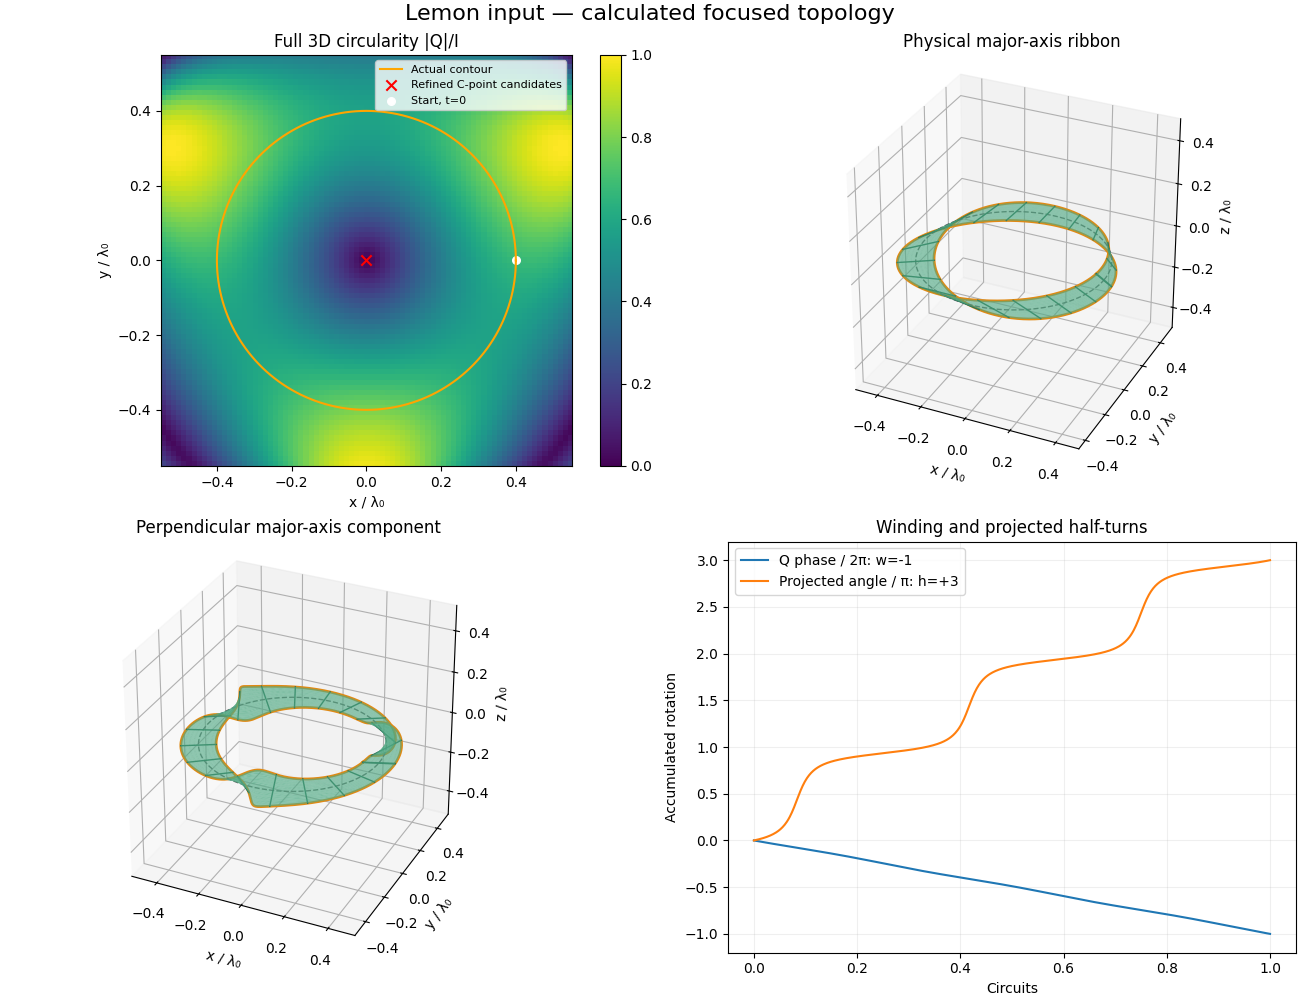

In [7]:
# Lemon: independent controls. Change these values and rerun this cell.
LEMON_RADIUS = .4
LEMON_CENTER = None
LEMON_WIDTH = .075
LEMON_AXIS = 'major'       # 'major' or 'minor'
LEMON_VIEW = 'perpendicular'  # 'physical' or 'perpendicular'
lemon_study = run_study('Lemon',radius=LEMON_RADIUS,center=LEMON_CENTER,
    width=LEMON_WIDTH,axis=LEMON_AXIS,view=LEMON_VIEW)

## 6. Star input — explicit topology study

$$\mathbf E_{in}=(U_{+1}\mathbf e_R+U_0\mathbf e_L)/\sqrt2.$$

The focused circular point can be displaced from the optical axis. The default contour follows the refined candidate rather than assuming that it remains at the origin.

Run the following cell independently after Sections 1–4. `CENTER=None` selects the refined C-point nearest the optical axis; set `(x,y)` to choose a different center. The overview always displays both full physical and projected major-axis ribbons. `AXIS` and `VIEW` select the animated ribbon. At **Circuits = 1.00**, compare the amber endpoint with its starting location; at **2.00**, check that it returns.

Star input: center=(-4.541815106642592e-12, 0.03174195856937113), radius=0.4 λ₀
Refined C-point candidates:
 [[-4.54181511e-12  3.17419586e-02]]
Q winding: 1 | Möbius parity (odd)
Minimum |Q|/I: 0.75032; minimum relative intensity: 0.5599

Axis                endpoint dot product     closure error
Major alpha          -1.000000000             0.00e+00
Minor beta           -1.000000000             0.00e+00
Spin normal gamma    +1.000000000             0.00e+00
Boundary components: 1
Minimum perpendicular director magnitude: 0.45706
Radial–axial major-axis half-turns: +1; minimum projected magnitude: 0.457063
Changing contour center, radius or optical parameters can change these results.
Minimum perpendicular director magnitude: 0.45706


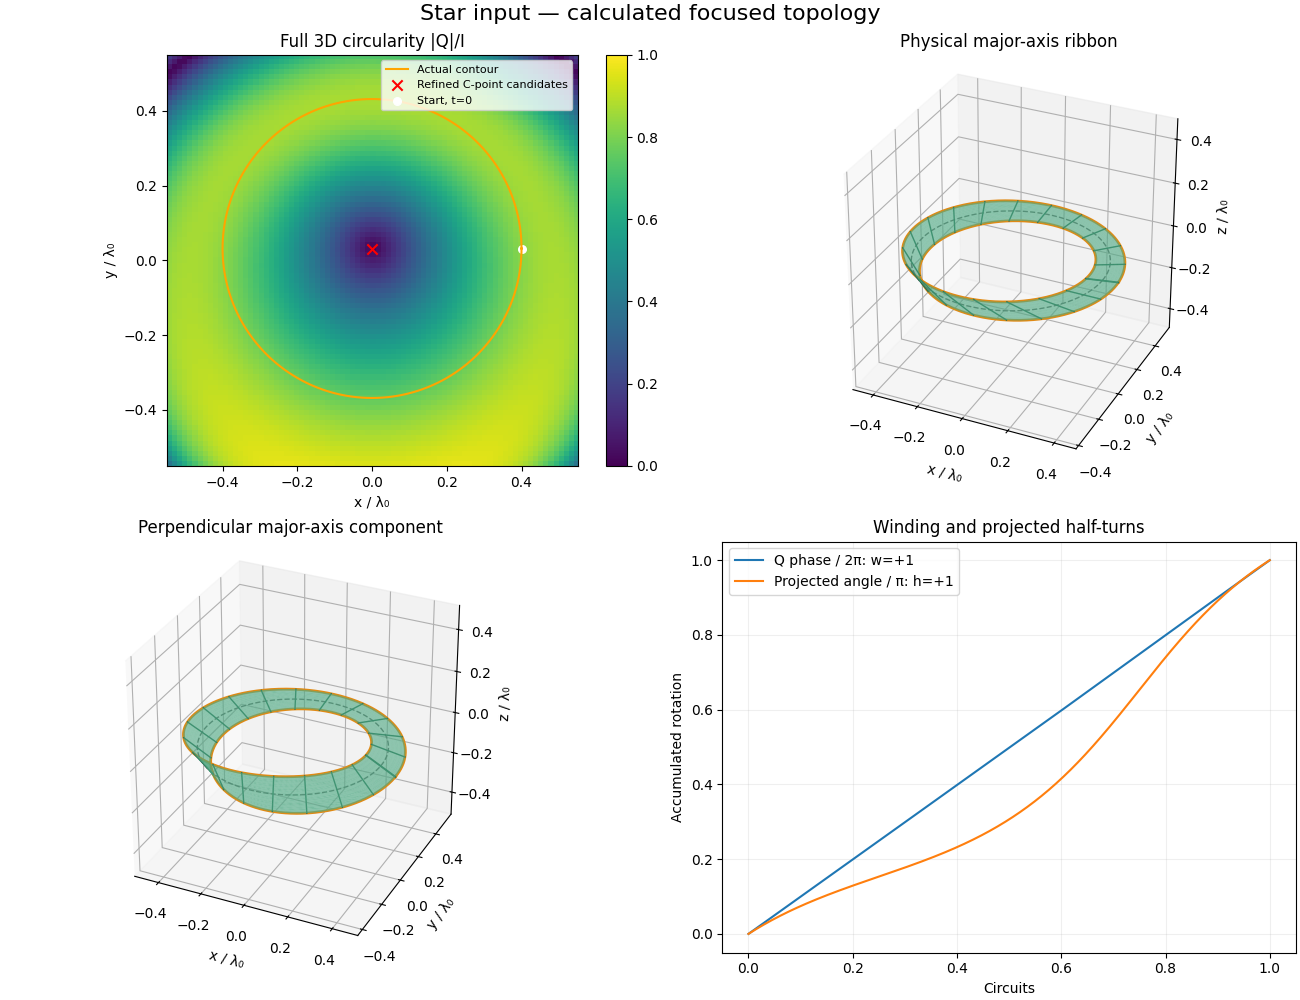

In [8]:
# Star: independent controls. Change these values and rerun this cell.
STAR_RADIUS = .4
STAR_CENTER = None
STAR_WIDTH = .075
STAR_AXIS = 'major'       # 'major' or 'minor'
STAR_VIEW = 'perpendicular'  # 'physical' or 'perpendicular'
star_study = run_study('Star',radius=STAR_RADIUS,center=STAR_CENTER,
    width=STAR_WIDTH,axis=STAR_AXIS,view=STAR_VIEW)

## 7. Monstar input — explicit topology study

$$\mathbf E_{in}=[(U_{+1}-U_{-1})\mathbf e_R/\sqrt2+U_0\mathbf e_L]/\sqrt2.$$

This is the symmetric equal-weight input used by the atlas. The label does not establish a focused monstar separatrix structure. Compare its anisotropy and projected rotation directly with the other cases.

Run the following cell independently after Sections 1–4. `CENTER=None` selects the refined C-point nearest the optical axis; set `(x,y)` to choose a different center. The overview always displays both full physical and projected major-axis ribbons. `AXIS` and `VIEW` select the animated ribbon. At **Circuits = 1.00**, compare the amber endpoint with its starting location; at **2.00**, check that it returns.

Monstar input: center=(-5.247290958810155e-12, 0.012232841971932763), radius=0.4 λ₀
Refined C-point candidates:
 [[-5.24729096e-12  1.22328420e-02]]
Q winding: 1 | Möbius parity (odd)
Minimum |Q|/I: 0.13933; minimum relative intensity: 0.58305

Axis                endpoint dot product     closure error
Major alpha          -1.000000000             3.68e-16
Minor beta           -1.000000000             3.95e-16
Spin normal gamma    +1.000000000             0.00e+00
Boundary components: 1
Minimum perpendicular director magnitude: 0.32033
Radial–axial major-axis half-turns: +1; minimum projected magnitude: 0.32033
Changing contour center, radius or optical parameters can change these results.
Minimum perpendicular director magnitude: 0.32033


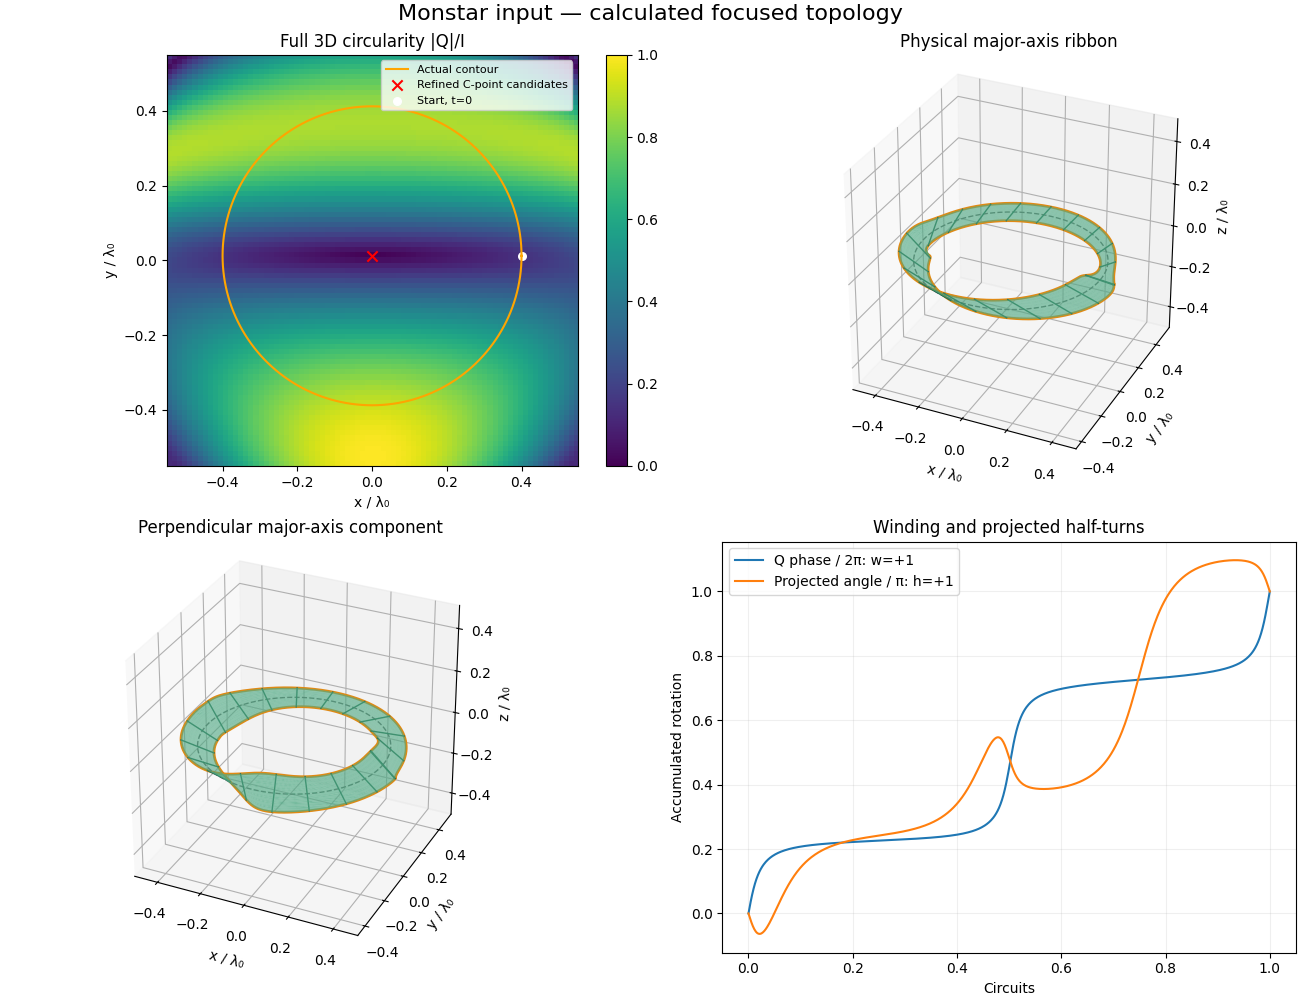

In [9]:
# Monstar: independent controls. Change these values and rerun this cell.
MONSTAR_RADIUS = .4
MONSTAR_CENTER = None
MONSTAR_WIDTH = .075
MONSTAR_AXIS = 'major'       # 'major' or 'minor'
MONSTAR_VIEW = 'perpendicular'  # 'physical' or 'perpendicular'
monstar_study = run_study('Monstar',radius=MONSTAR_RADIUS,center=MONSTAR_CENTER,
    width=MONSTAR_WIDTH,axis=MONSTAR_AXIS,view=MONSTAR_VIEW)

## 8. Compare calculated structures
This table uses the studies you have actually run. The signed half-turn count uses the major axis in the radial–axial frame defined above. It is distinct from Q winding. The number of boundary components follows the measured director parity, with mesh connectivity checked below.

In [10]:
def comparison_table():
    rows=['| Input | Center (x,y) / λ₀ | Q winding | Projected half-turns | Major closure | Minor closure | Normal closure | Boundary components |',
          '| --- | --- | --- | --- | --- | --- | --- | --- |']
    def closure(v):
        norms=np.linalg.norm(v,axis=1)
        return 'undefined' if norms.min()<1e-7 else f'{np.dot(v[0],v[-1])/(norms[0]*norms[-1]):+.3f}'
    for name in ['Lemon','Star','Monstar']:
        if name not in RESULTS:continue
        r=RESULTS[name];c=r['c']
        rows.append(f'| {name} | ({r["center"][0]:.5f}, {r["center"][1]:.5f}) | {c["w"]:+d} | {r["halfturns"]:+d} | {closure(c["a"])} | {closure(c["b"])} | {closure(c["g"])} | {1 if c["w"]%2 else 2} |')
    display(Markdown('\n'.join(rows)))
comparison_table()

<IPython.core.display.Markdown object>


| Input | Q winding | Projected half-turns | Boundary components |
| --- | --- | --- | --- |
| Lemon | -1 | +3 | 1 |
| Star | +1 | +1 | 1 |
| Monstar | +1 | +1 | 1 |

## 9. Verify each study
For every case already run, refine polar quadrature and the contour independently, compare complex fields, and check both rotation counts. The mesh check counts actual boundary components and rejects nonmanifold edges. These are numerical consistency checks, not an independent validation of the optical focusing theory. A zero change on refinement cannot establish that the physical model matches an experiment.

In [11]:
def mesh_boundary_components(c,width):
    from collections import Counter
    vertices,faces=mobius_mesh(c,width)
    edges=Counter(tuple(sorted((int(a),int(b)))) for face in faces for a,b in zip(face,np.roll(face,-1)))
    if max(edges.values())>2:raise AssertionError('Nonmanifold mesh edge')
    adjacency={}
    for (a,b),count in edges.items():
        if count==1:adjacency.setdefault(a,[]).append(b);adjacency.setdefault(b,[]).append(a)
    assert adjacency and all(len(v)==2 for v in adjacency.values())
    seen=set();components=0
    for node in adjacency:
        if node in seen:continue
        components+=1;todo=[node]
        while todo:
            node=todo.pop()
            if node in seen:continue
            seen.add(node);todo.extend(adjacency[node])
    return components

for name,r in RESULTS.items():
    c=r['c'];nt=r['nt'];samples=r['samples']
    angular=contour(r['terms'],r['radius'],r['center'],samples=samples,nt=2*nt-1)
    refined=contour(r['terms'],r['radius'],r['center'],samples=2*samples-1,nt=nt)
    relative=np.linalg.norm(c['E']-angular['E'])/np.linalg.norm(angular['E'])
    h1=projected_rotation(angular)[1];h2=projected_rotation(refined)[1]
    assert angular['w']==refined['w']==c['w']
    assert h1==h2==r['halfturns']
    boundary=mesh_boundary_components(c,r['width'])
    assert boundary==(1 if c['w']%2 else 2)
    assert relative<1e-6,'Polar quadrature has not converged'
    print(f'{name}: field change={relative:.3e}; Q winding={c["w"]:+d}; projected half-turns={h1:+d}; boundary components={boundary}')

Lemon: field change=1.768e-12; Q winding=-1; projected half-turns=+3; boundary components=1
Star: field change=1.763e-12; Q winding=+1; projected half-turns=+1; boundary components=1
Monstar: field change=1.766e-12; Q winding=+1; projected half-turns=+1; boundary components=1


### Optional: vary the radius around each selected C-point
A singularity crossing, loss of intensity, or vanishing projection can change the result or invalidate a contour. Missing points are rejected calculations. This sweep uses each study's chosen center and the major axis.

In [12]:
RUN_RADIUS_SWEEP = False
if RUN_RADIUS_SWEEP:
    radii=np.linspace(.04,.8,39)
    fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    for name,r in RESULTS.items():
        winding=[];halfturns=[]
        for radius in radii:
            try:c=contour(r['terms'],radius,r['center'],samples=721,nt=401);winding.append(c['w'])
            except ValueError:winding.append(np.nan);halfturns.append(np.nan);continue
            try:halfturns.append(projected_rotation(c)[1])
            except ValueError:halfturns.append(np.nan)
        axs[0].plot(radii,winding,'.-',label=name);axs[1].plot(radii,halfturns,'.-',label=name)
    for ax,label in zip(axs,['Q winding','Radial–axial half-turns']):
        ax.set(xlabel='Radius / λ₀',ylabel=label);ax.legend();ax.grid(alpha=.2)
    plt.show()

## 10. Export the three studies
Set `EXPORT_STUDIES=True` to save an independent animated HTML viewer and a static overview for each case already calculated. The HTML includes Plotly and runs without a Python kernel. File names record the selected animated axis and view. Run the named study again after changing parameters before exporting.

In [13]:
EXPORT_STUDIES = False
if EXPORT_STUDIES:
    import zipfile
    paths=[]
    for name,r in RESULTS.items():
        stem=f'03_{name}_{r["axis"]}_{r["view"]}'
        html=Path(stem+'.html');r['viewer'].write_html(str(html),include_plotlyjs=True,auto_play=False);paths.append(html)
        png=Path(f'03_{name}_Overview.png');r['overview'].savefig(png,dpi=160);paths.append(png)
    if not paths:raise ValueError('Run at least one named study first')
    archive=Path('03_Topology_Studies.zip')
    with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as zf:
        for path in paths:zf.write(path,path.name)
    try:
        from google.colab import files
        files.download(str(archive))
    except ImportError:
        from IPython.display import FileLink
        display(FileLink(str(archive)))

## 11. Interpretation and further work
The study distinguishes incident texture names, focused C-point locations, director nonorientability, and rotation in a specified projection. To identify focused lemon, star or monstar morphologies, add a local polarization-line and separatrix analysis around the chosen singularity. A half-turn count from this planar radial–axial construction should not be equated with every three-dimensional ribbon index in the literature.

A physical ribbon can self-intersect even when the mesh has the correct nonorientable connectivity. The projected view provides a clear geometric comparison only while its transverse magnitude stays nonzero. The directed spin normal remains single-valued wherever defined. The major and minor axes can reverse sign around a C-point, whereas neither principal axis is defined at the C-point itself.

The solver accepts axial position, but the named studies above use z=0. Tracing C-lines, choosing planes normal to them, and validating against an independent two-angle Richards–Wolf integral are useful next steps. The pupil modes are not normalized to equal powers; all topology here is evaluated from coherent complex fields.